# Notes on Python

## Data types

### tuple

1. create
    ```
    a = tuple(range(10))
    ```

2. slice

    `a[start:end:step]`


### list

1. create
    ```
    a = [i for i in range(10)]
    b = list((1, 2, 3, 4))
    ```

2. slice

    `a[start:end:step]`

    ```
    a[::2]
    a[1:3]
    a[:3]
    a[-2:]
    ```


3. Inverse an array

    ```
    a = [1, 2, 3]
    b = a[::-1]
    print(a)
    print(b)
    ```

### dict

1. create
    ```
    a = {'name': 'Yang Zongze', 'id': 1234, 'department': 'AMA'}
    ```

2. get item
    ```
    a['name']
    a.get('age', 30)
    ```

    ```
    for k, v in a.items():
        print(k, v)
    ```

a = {'name': 'Yang Zongze', 'id': 1234, 'department': 'AMA'}
for k, v in a.items():
    print(k, v)

## Builtin functions

### `map`

    ```
    s = map(lambda x, y: x+y, [1, 2, 3], [4, 5, 6])
    for i in s:
        print(i)
    ```

### `reduce`

    ```
    from functools import reduce
    from operator import add, mul
    from math import sin

    # reduce(lambda x, y: x+y, [1, 2, 3, 4, 5])

    # sin(1)*sin(2)*sin(3)
    reduce(mul, map(sin, [1, 2, 3]))
    ```

## Packages

### os, sys

In [15]:
import os
import sys

# walk
# path
# join
for pth, dirs, files in os.walk('.'):
    print(pth, dirs, files)
    break

. [] ['python_notes.ipynb', 'jupyter_book.md']


In [16]:
## set environment
os.environ['ABC'] = '3'

### signal

In [17]:
import signal
from time import sleep

gframe = None
def handler(sig_num, frame):
    global gframe
    print('Sig received with number %d'%sig_num)
    gframe = frame

signal.signal(signal.SIGINT, handler)

print('Start ...')
signal.raise_signal(2)
print('End ...')

Start ...
Sig received with number 2
End ...


In [18]:
gframe

<frame at 0x110baf320, file '/var/folders/tf/v4zjvtw12yb3tszk813gmnvw0000gn/T/ipykernel_63421/3869011539.py', line 13, code <module>>

### numpy

In [19]:
import numpy as np

In [20]:
np.isinf(np.inf) or np.isnan

np.True_

### psutil

In [21]:
import os
import psutil
pid = os.getpid()
python_process = psutil.Process(pid)
memoryUse = python_process.memory_info()

In [22]:
memoryUse

pmem(rss=151994368, vms=446060953600, pfaults=17296, pageins=49)

### Json

```python
import base64
import json
import numpy as np

class MyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, complex):
            return str(obj)
        
        return json.JSONEncoder(self, obj)

json._default_encoder = MyEncoder()
```

## Package not in standard path

### Load package
Some times we would like to import files from other folds

1. First add the path to system path by
2. Import the package

In [23]:
import os
import sys 
mypath = '../firedrake/py'  # the path of your file
sys.path.append(mypath) # ma

from intro_utils import plot_mesh_with_label

### Reload package

```
import some_package
import importlib

some_package = importlib.reload(some_package)
```

## tqdm

### How to use tqdm

In [ ]:
from tqdm import tqdm
from time import sleep

pbar = tqdm(["a", "b", "c", "d"])
for char in pbar:
    sleep(0.25)
    pbar.set_description("Processing %s" % char)

### Progress bar in parallel

In [ ]:
import mpi4py
from tqdm.auto import tqdm

def isnotebook():
    try:
        shell = get_ipython().__class__.__name__
        if shell == 'ZMQInteractiveShell':
            return True   # Jupyter notebook or qtconsole
        elif shell == 'TerminalInteractiveShell':
            return False  # Terminal running IPython
        else:
            return False  # Other type (?)
    except NameError:
        return False      # Probably standard Python interpreter


class ptqdm:
    
    __config__ = {'ncols': None if isnotebook() else 100, 'ascii': True}
    
    def __init__(self, *args, **kwargs):
        
        comm = kwargs['comm'] if 'comm' in kwargs.keys() else None
        comm = comm or mpi4py.MPI.COMM_WORLD
        self.rank = comm.Get_rank()  
        
        for key, val in ptqdm.__config__.items():
            if key not in kwargs.keys():
                kwargs[key] = val
        
        self.tqdm = tqdm(*args, **kwargs) if self.rank == 0 else None
    
    def update(self):
        if self.tqdm is not None:
            self.tqdm.update()
            
    def close(self):
        if self.tqdm is not None:
            self.tqdm.close()
        
    def __getattr__(self, attr):
        return self.tqdm.__get_attr__(attr)

## Command Line options

### How to use `getopt`

```python
import os
import sys
import numpy as np


import getopt

if __name__ == '__main__':
    try:
        opts, args = getopt.getopt(sys.argv[1:], '', ["lcs=","full-path="])
    except getopt.GetoptError:
        print('%s --lcs <[python list]> --full-path <full-path>' % sys.argv[0])
        sys.exit(2)

    for opt, arg in opts:
        if opt == '--lcs':
            print('lcs arg is %s' % arg)
        elif opt == '--full-path':
            print('path arg is %s' % arg)
```

### How to use `argparse`
```python
import os
import sys
import numpy as np


import argparse

if __name__ == '__main__':
    parser = argparse.ArgumentParser(description='Learn Argparse')
    parser.add_argument('--lcs', metavar='lcs', type=float, nargs='+', # default=None,
                        help='A python list of mesh sizes.')
    parser.add_argument('--fullpath', dest='full_path', action='store',
                        default=None,
                        help='The path where data stay.')

    
    args = parser.parse_args()
    print(args)
```

In [ ]:
import os
import sys
import numpy as np


import argparse


parser = argparse.ArgumentParser(description='Learn Argparse')
parser.add_argument('--lcs', metavar='lcs', type=float, nargs='+', # default=None,
                    help='A python list of mesh sizes.')
parser.add_argument('--fullpath', dest='full_path', action='store',
                    default=None,
                    help='The path where data stay.')


# args = parser.parse_args()
# print(args)
    
parser.parse_known_args('--lcs 1 -b'.split())

In [ ]:
arg, unknow = parser.parse_known_args(''.split())
print((arg, unknow))

In [ ]:
arg, unknow = parser.parse_known_intermixed_args(''.split())
print((arg, unknow))

## Matplotlib

### Basic usage

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import numpy as np

matplotlib.rcParams.update(
    {'font.size': 16, 
     'savefig.bbox': 'tight',
     "figure.facecolor":  (0.9, 0.9, 0.9, 0.3),  # red   with alpha = 30%
     "axes.facecolor":    (0.8, 0.8, 0.8, 0.2),  # green with alpha = 50%
     # "savefig.facecolor": (0.0, 0.0, 1.0, 0.2),  # blue  with alpha = 20%
    }
)

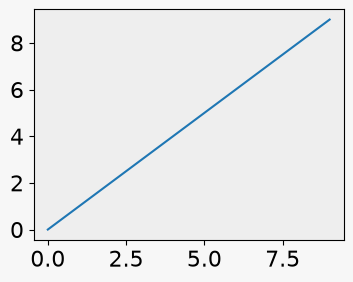

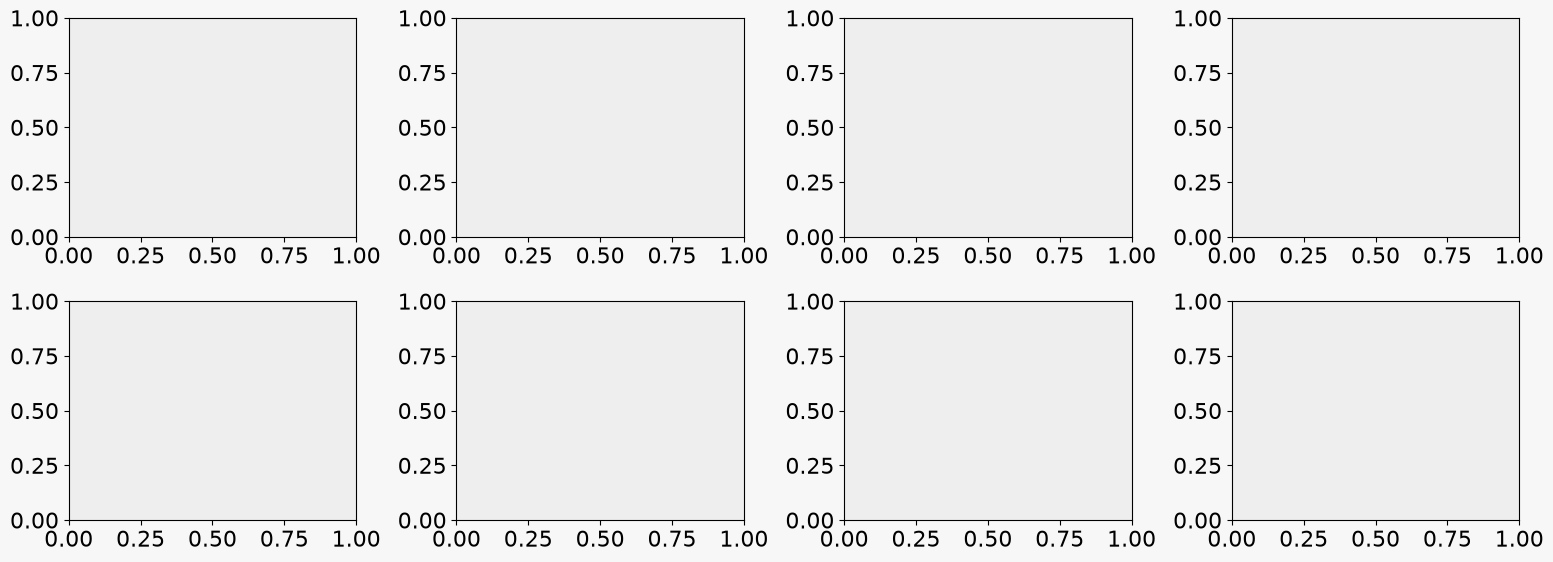

In [ ]:
# create fig with size 7X8 (in inches)   and 1inch = 2.54cm
# figsize = [width, height]
fig1 = plt.figure(figsize=[4, 3])

# fig1.patch.set_facecolor('#E0E0E0')
# fig1.patch.set_alpha(0.7)
ax1 = fig1.add_subplot()   # default will same as add_subplot(1, 1, 1)
ax1.plot(range(10))

# or just change to cm by this way
cm = 1/2.54 # inch
fig2 = plt.figure(figsize=[40*cm, 15*cm])
ax2 = fig2.subplots(2, 4)

fig2.tight_layout()   # Otherwise the subplots will overlap

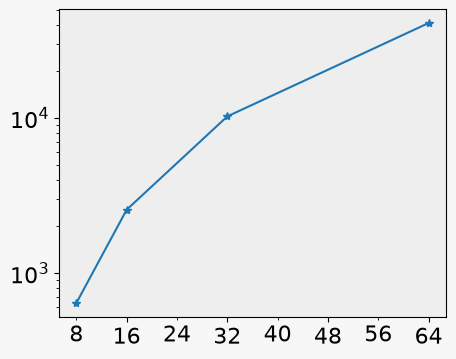

In [ ]:
x = [8*2**i for i in range(4)]
y = [10*_**2 for _ in x]

fig, ax = plt.subplots(figsize=(5, 4))
ax.semilogy(x, y, '-*')

ax.xaxis.set_major_locator(ticker.MultipleLocator(base=16))
ax.xaxis.set_minor_locator(ticker.MultipleLocator(base=8))

ax.xaxis.set_major_formatter(ticker.FormatStrFormatter('%g'))
ax.xaxis.set_minor_formatter(ticker.FormatStrFormatter('%g'))

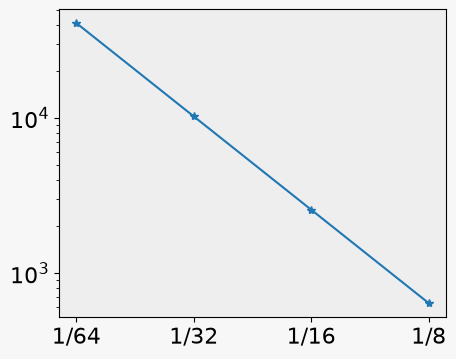

In [ ]:
x = [8*2**i for i in range(4)]
x_inv = [1/_ for _ in x]
y = [10*_**2 for _ in x]

fig = plt.figure(figsize=[5, 4])
ax = fig.add_subplot()
ax.loglog(x_inv, y, '-*')

ax.xaxis.set_major_locator(ticker.LogLocator(base=2))
ax.xaxis.set_minor_locator(ticker.LogLocator(base=2))

if True:
    def ticker_str(x, pos):
        if x < 1:
            n = int(np.round(1/x))
            return "1/%g"%n
        return  "%g"%x 

    ax.xaxis.set_major_formatter(ticker_str)
    ax.xaxis.set_minor_formatter(ticker_str)
else:
    ax.xaxis.set_major_formatter(ticker.LogFormatterSciNotation(2))
    ax.xaxis.set_minor_formatter(ticker.LogFormatterSciNotation(2))


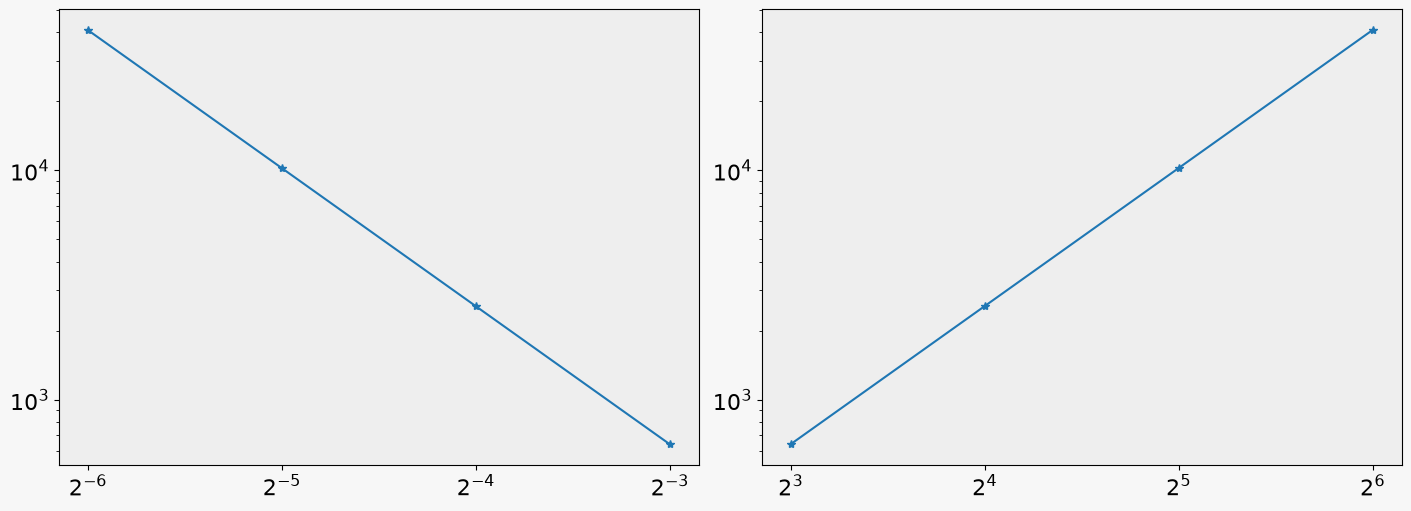

In [ ]:
fig, [ax1, ax2] = plt.subplots(
    nrows=1, ncols=2,
    figsize=(14, 5),
    constrained_layout=True,
)
ax1.loglog(x_inv, y, '-*')
ax1.set_xscale('log', base=2)

ax2.loglog(x, y, '-*')
ax2.set_xscale('log', base=2)

In [ ]:
def setup(ax):
    ax.spines['right'].set_color('none')
    ax.spines['left'].set_color('none')
    ax.yaxis.set_major_locator(ticker.NullLocator())
    ax.spines['top'].set_color('none')
    ax.xaxis.set_ticks_position('bottom')
    ax.tick_params(which='major', width=1.00, length=5)
    ax.tick_params(which='minor', width=0.75, length=2.5, labelsize=10)
    ax.set_xlim(0, 5)
    ax.set_ylim(0, 1)
    ax.patch.set_alpha(0.0)

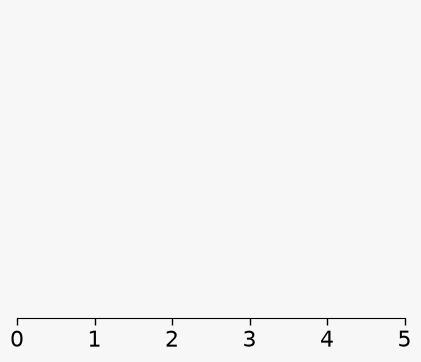

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))
setup(ax)

### Plot errors with reference line

In [ ]:
def minor_tick(x, pos):
    if x < 0.1:
        if (np.round(x*100) in [4, 6]):
            return '%.2f' %x
        else:
            return ''
            
    return '%.1f' %x


order = 1

dim = 3
lcs =  [0.125, 0.0625, 0.03125, 0.015625] # Gmsh lcs
ndofs =  [628, 3603, 23472, 164356] # Number of dofs
errors =  [0.04827200204462808, 0.013616633838663416, 0.0033094536713063377, 0.0008433901100836445] # Errors compared with Ref sol
filename = None

p = order + 1
c01 = 2
c02 = -1

x1 = ndofs
x2 = lcs
y = errors

        
c1 = y[-1]/(x1[-1]**(-p/dim)) + c01
c2 = y[-1]/(x2[-1]**p) + c02

y1_ref = [c1*_**(-p/dim) for _ in x1]
y2_ref = [c2*_**p for _ in x2]
fig = plt.figure() # (figsize=[4,3])
ax = fig.add_subplot()
ax.loglog(x1, y, 'd-', x1, y1_ref, '--')
ax.set_xlabel('Number of DOFs')
ax.set_ylabel('$L^2$ errors')
ax.text(x1[-2], y1_ref[-2], '$O(h^%d)$'%p, va='bottom', ha='left')

filename and fig.savefig(filename + '-ndofs.eps', format='eps')

fig = plt.figure() # (figsize=[4,3])
ax = fig.add_subplot()
ax.loglog(x2, y, 'd-', x2, y2_ref, '--')
ax.set_xlabel('Mesh size')
ax.set_ylabel('$L^2$ errors')
ax.text(x2[2], y2_ref[2], '$O(h^%d)$'%p, va='top', ha='left')

ax.xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%.1f'))
ax.xaxis.set_minor_formatter(minor_tick)

filename and fig.savefig(filename + '-maxh.eps', format='eps')

if filename:
    print('filename1: ' + filename + '-ndofs.eps')
    print('filename2: ' + filename + '-maxh.eps')

In [ ]:
help(fig.autofmt_xdate)

## Onedrive API

### Download from onedrive

In [ ]:
share_url = 'https://1drv.ms/u/s!Au1wcoQGYu6djJofAu3qVd577D-xgg?e=wASCui'

In [ ]:
import base64
def create_onedrive_directdownload (onedrive_link):
    data_bytes64 = base64.b64encode(bytes(onedrive_link, 'utf-8'))
    data_bytes64_String = data_bytes64.decode('utf-8').replace('/','_').replace('+','-').rstrip("=")
    resultUrl = f"https://api.onedrive.com/v1.0/shares/u!{data_bytes64_String}/root/content"
    return resultUrl

In [ ]:
create_onedrive_directdownload(share_url)

### Uploader

In [ ]:
# file: uploader
import os
import requests
import tqdm
import click

# Here, we get the token from https://developer.microsoft.com/en-us/graph/graph-explorer
# and save it in file access_token
# TODO: get the token automaticly.
def load_access_token(path=None):
    if path is None:
        path = os.getcwd()
    with open(os.path.join(path, "access_token"), "r") as f:
        access_token = f.readline().strip('\n')

    return access_token


def upload(file_to_upload, file_name, access_token, unit=1):
    local_name = file_to_upload

    if file_name is None:
        file_name = os.path.basename(local_name)


    request_body = {
    }

    base_url = "https://graph.microsoft.com/v1.0"
    # folder_id = "01VGN2QX6TWD75CHGPGRG2UCZAOOHFOKEM"

    url_put = base_url + f"/me/drive/root:/{file_name}:/createUploadSession"

    headers = {
        "Authorization": "Bearer " + access_token
    }

    response_upload_session = requests.post(
        url_put, headers=headers, json=request_body
    )

    try:
        upload_url = response_upload_session.json()['uploadUrl']
    except Exception as e:
        raise e

    with open(local_name, "rb") as upload:
        total_file_size = os.path.getsize(local_name)
        chunk_size = 327680*unit
        chunk_number = total_file_size // chunk_size
        chunk_leftover = total_file_size - chunk_size * chunk_number
        counter = 0
        
        bar = tqdm.tqdm(total=chunk_number + 1, 
                        desc="upload")

        while True:
            chunk_data = upload.read(chunk_size)
            start_index = counter * chunk_size
            end_index = start_index + chunk_size

            if not chunk_data:
                break

            if counter == chunk_number:
                end_index = start_index + chunk_leftover

            upload_headers = {
                "Content-Length": f'{chunk_size}',
                "Content-Range": f'bytes {start_index}-{end_index-1}/{total_file_size}'
            }

            chunk_data_upload_status = requests.put(
                upload_url, 
                headers=upload_headers,
                data=chunk_data)
            # print('Upload Progress: {0}'.format(chunk_data_upload_status.json()['nextExpectedRanges']))
            bar.update()

            counter += 1
        bar.close()
        
    requests.delete(upload_url)


@click.command()
@click.option('--token_path', default=None, help='access_token path')
@click.option('--unit', default=16, help='access_token path')
@click.option('--name', default=None, help='remote file name')
@click.argument('file_to_upload')
def main(file_to_upload, name, token_path, unit):
    token = load_access_token(token_path)
    print(token)
    upload(file_to_upload, name, token, unit)

# if __name__ == '__main__':
#     main()

## GC

Ref:

1. https://devguide.python.org/internals/garbage-collector/index.html
1. https://jakevdp.github.io/blog/2014/05/09/why-python-is-slow/
2. https://zhuanlan.zhihu.com/p/295062531

### `id`

In [ ]:
str1_addr = id('abc')
str2_addr = id('abc')

In [ ]:
print(f"str1 addr: {str1_addr}, str2 addr: {str2_addr}")
str1_addr == str2_addr

In [ ]:
# WARNNG: never do this!

import ctypes

class IntStruct(ctypes.Structure):
    _fields_ = [("ob_refcnt", ctypes.c_long),
                ("ob_type", ctypes.c_void_p),
                ("ob_size", ctypes.c_ulong),
                ("ob_digit", ctypes.c_long)]
    
    def __repr__(self):
        return ("IntStruct(ob_digit={self.ob_digit}, "
                "refcount={self.ob_refcnt})").format(self=self)

c113 = ctypes.c_long(113)
iptr = IntStruct.from_address(id(113))
print(f"113 == 4 is {113 == 4}")
print(f"id(4) = {id(4)}, id(113) = {id(113)}")

# be careful, remember restore the value, or restart the interpreter
iptr.ob_digit = 4  # now Python's 113 contains a 4!
print(f"113 == 4 is {113 == 4}")
print(f"id(4) = {id(4)}, id(113) = {id(113)}")

# restore the value
iptr.ob_digit = c113
print(f"113 == 4 is {113 == 4}")
print(f"id(4) = {id(4)}, id(113) = {id(113)}")

In [ ]:
import ctypes
import gc
gc.disable()

class Object(ctypes.Structure):
    _fields_ = [("ob_refcnt", ctypes.c_long)]

In [ ]:
l = []
l.append(l)

In [ ]:
l_addr = id(l)

In [ ]:
l_addr

In [ ]:
del l

In [ ]:
Object.from_address(l_addr).ob_refcnt